# Phase 4 — Short interest (descriptive, no backtest)

Pre-registered in `EXPERIMENTS.md` (2026-10-10 14:47 CEST) before computing. The data (2025-10-15 → 2026-09-30) lie in the OOS period; this is legitimate now because the single OOS run of the static strategy has been done and no parameter will change. Counters unchanged (11 IS backtests, 1 OOS access).

- **Data:** Nasdaq short interest for INTC and AMD (raw JSON already in `data/raw/`, 24 semi-monthly settlement dates each).
- **Alignment (main):** publication date ≈ settlement + 7 business days (first trading day on or after it). Settlement-date alignment: descriptive only.
- **Three questions, five Spearman tests, n = 23 periods:** (Q1) each stock's SI change vs the spread change; (Q2) SI change INTC − AMD vs the spread change; (Q3) each stock's SI change vs the largest absolute daily return of the two stocks in the period.
- **Limitations:** 23 observations (very low power), 5 tests (multiple comparisons; Bonferroni threshold 0.01 shown), one year only, approximate publication lag.

In [1]:
import logging
from datetime import date

import pandas as pd
import plotly.graph_objects as go
from IPython.display import Image, display
from plotly.subplots import make_subplots

from pairs.config import SPLIT_DATE, TICKER_A, TICKER_B
from pairs.data import load_pair
from pairs.plotting import DERIVED_COLOR, SERIES_COLORS, apply_style, save_figure
from pairs.short_interest import (
    build_periods,
    critical_spearman,
    days_to_cover_floor,
    load_short_interest,
    next_trading_day,
    publication_dates,
    spearman_tests,
)
from pairs.spread import compute_spread, fit_hedge_ratio

logging.basicConfig(level=logging.INFO, format="%(levelname)s %(name)s: %(message)s")
for noisy in ("kaleido", "choreographer"):
    logging.getLogger(noisy).setLevel(logging.WARNING)

PRICE_END = date(2026, 10, 10)  # exclusive: last available price date is 2026-10-09

In [2]:
si = {t: load_short_interest(t) for t in (TICKER_A, TICKER_B)}
assert all(len(v) == 24 for v in si.values())
assert si[TICKER_A].index.equals(si[TICKER_B].index)

prices = load_pair(end=PRICE_END)
fit = fit_hedge_ratio(prices, end=SPLIT_DATE)  # static beta, IS only
assert round(fit.beta, 4) == 1.0471

settle = pd.DatetimeIndex(si[TICKER_A].index)
pub = publication_dates(settle)
anchors = next_trading_day(pub, pd.DatetimeIndex(prices.index))
calendar = pd.DataFrame(
    {
        "settlement": settle.date,
        "publication (≈ +7 bdays)": pub.date,
        "trading-day anchor": anchors.date,
    }
)
print(f"Settlement dates: {settle[0].date()} -> {settle[-1].date()} ({len(settle)} dates)")
print(f"Publication anchors: {anchors[0].date()} -> {anchors[-1].date()}")
calendar

INFO pairs.short_interest: INTC short interest: 24 dates, 2025-10-15 -> 2026-09-30 (INTC_short_interest_nasdaq_20261010T082049Z.json)


INFO pairs.short_interest: AMD short interest: 24 dates, 2025-10-15 -> 2026-09-30 (AMD_short_interest_nasdaq_20261010T082049Z.json)


INFO pairs.data: Loaded INTC/AMD: 11737 common days, 1980-03-17 -> 2026-10-09 (end=2026-10-10, exclusive)


INFO pairs.spread: Hedge fit (log prices) INTC ~ AMD on 1980-03-17..2012-12-31: alpha=-1.2311 beta=1.0471 R2=0.1499


Settlement dates: 2025-10-15 -> 2026-09-30 (24 dates)
Publication anchors: 2025-10-24 -> 2026-10-09


,settlement,publication (≈ +7 bdays),trading-day anchor
0,2025-10-15,2025-10-24,2025-10-24
1,2025-10-31,2025-11-11,2025-11-11
2,2025-11-14,2025-11-25,2025-11-25
3,2025-11-28,2025-12-09,2025-12-09
4,2025-12-15,2025-12-24,2025-12-24
5,2025-12-31,2026-01-09,2026-01-09
6,2026-01-15,2026-01-26,2026-01-26
7,2026-01-30,2026-02-10,2026-02-10
8,2026-02-13,2026-02-24,2026-02-24
9,2026-02-27,2026-03-10,2026-03-10


### Data-quality flag: days to cover exactly 1.0 (probable floor of the source)

In [3]:
floor = {t: days_to_cover_floor(v) for t, v in si.items()}
pd.DataFrame(
    {
        "n dates with days_to_cover == 1.0": {t: len(d) for t, d in floor.items()},
        "out of": {t: len(v) for t, v in si.items()},
        "settlement dates": {t: ", ".join(str(x.date()) for x in d) for t, d in floor.items()},
    }
)

,n dates with days_to_cover == 1.0,out of,settlement dates
INTC,6,24,"2025-10-15, 2025-10-31, 2026-01-30, 2026-04-30..."
AMD,9,24,"2025-10-15, 2025-10-31, 2025-11-14, 2025-11-28..."


## Short interest (indexed to 100) and the spread, on the same time axis

Top: short interest of each stock, placed on its approximate **publication** date, indexed to 100 at the first date. Bottom: daily log spread `log P_INTC − 1.047·log P_AMD` (static IS β). Two panels instead of two y-axes.

INFO pairs.plotting: Saved figure 04a_short_interest_spread (.html, .png) in C:\Users\cloti\Documents\Projects\challenge_BSQ\reports\figures


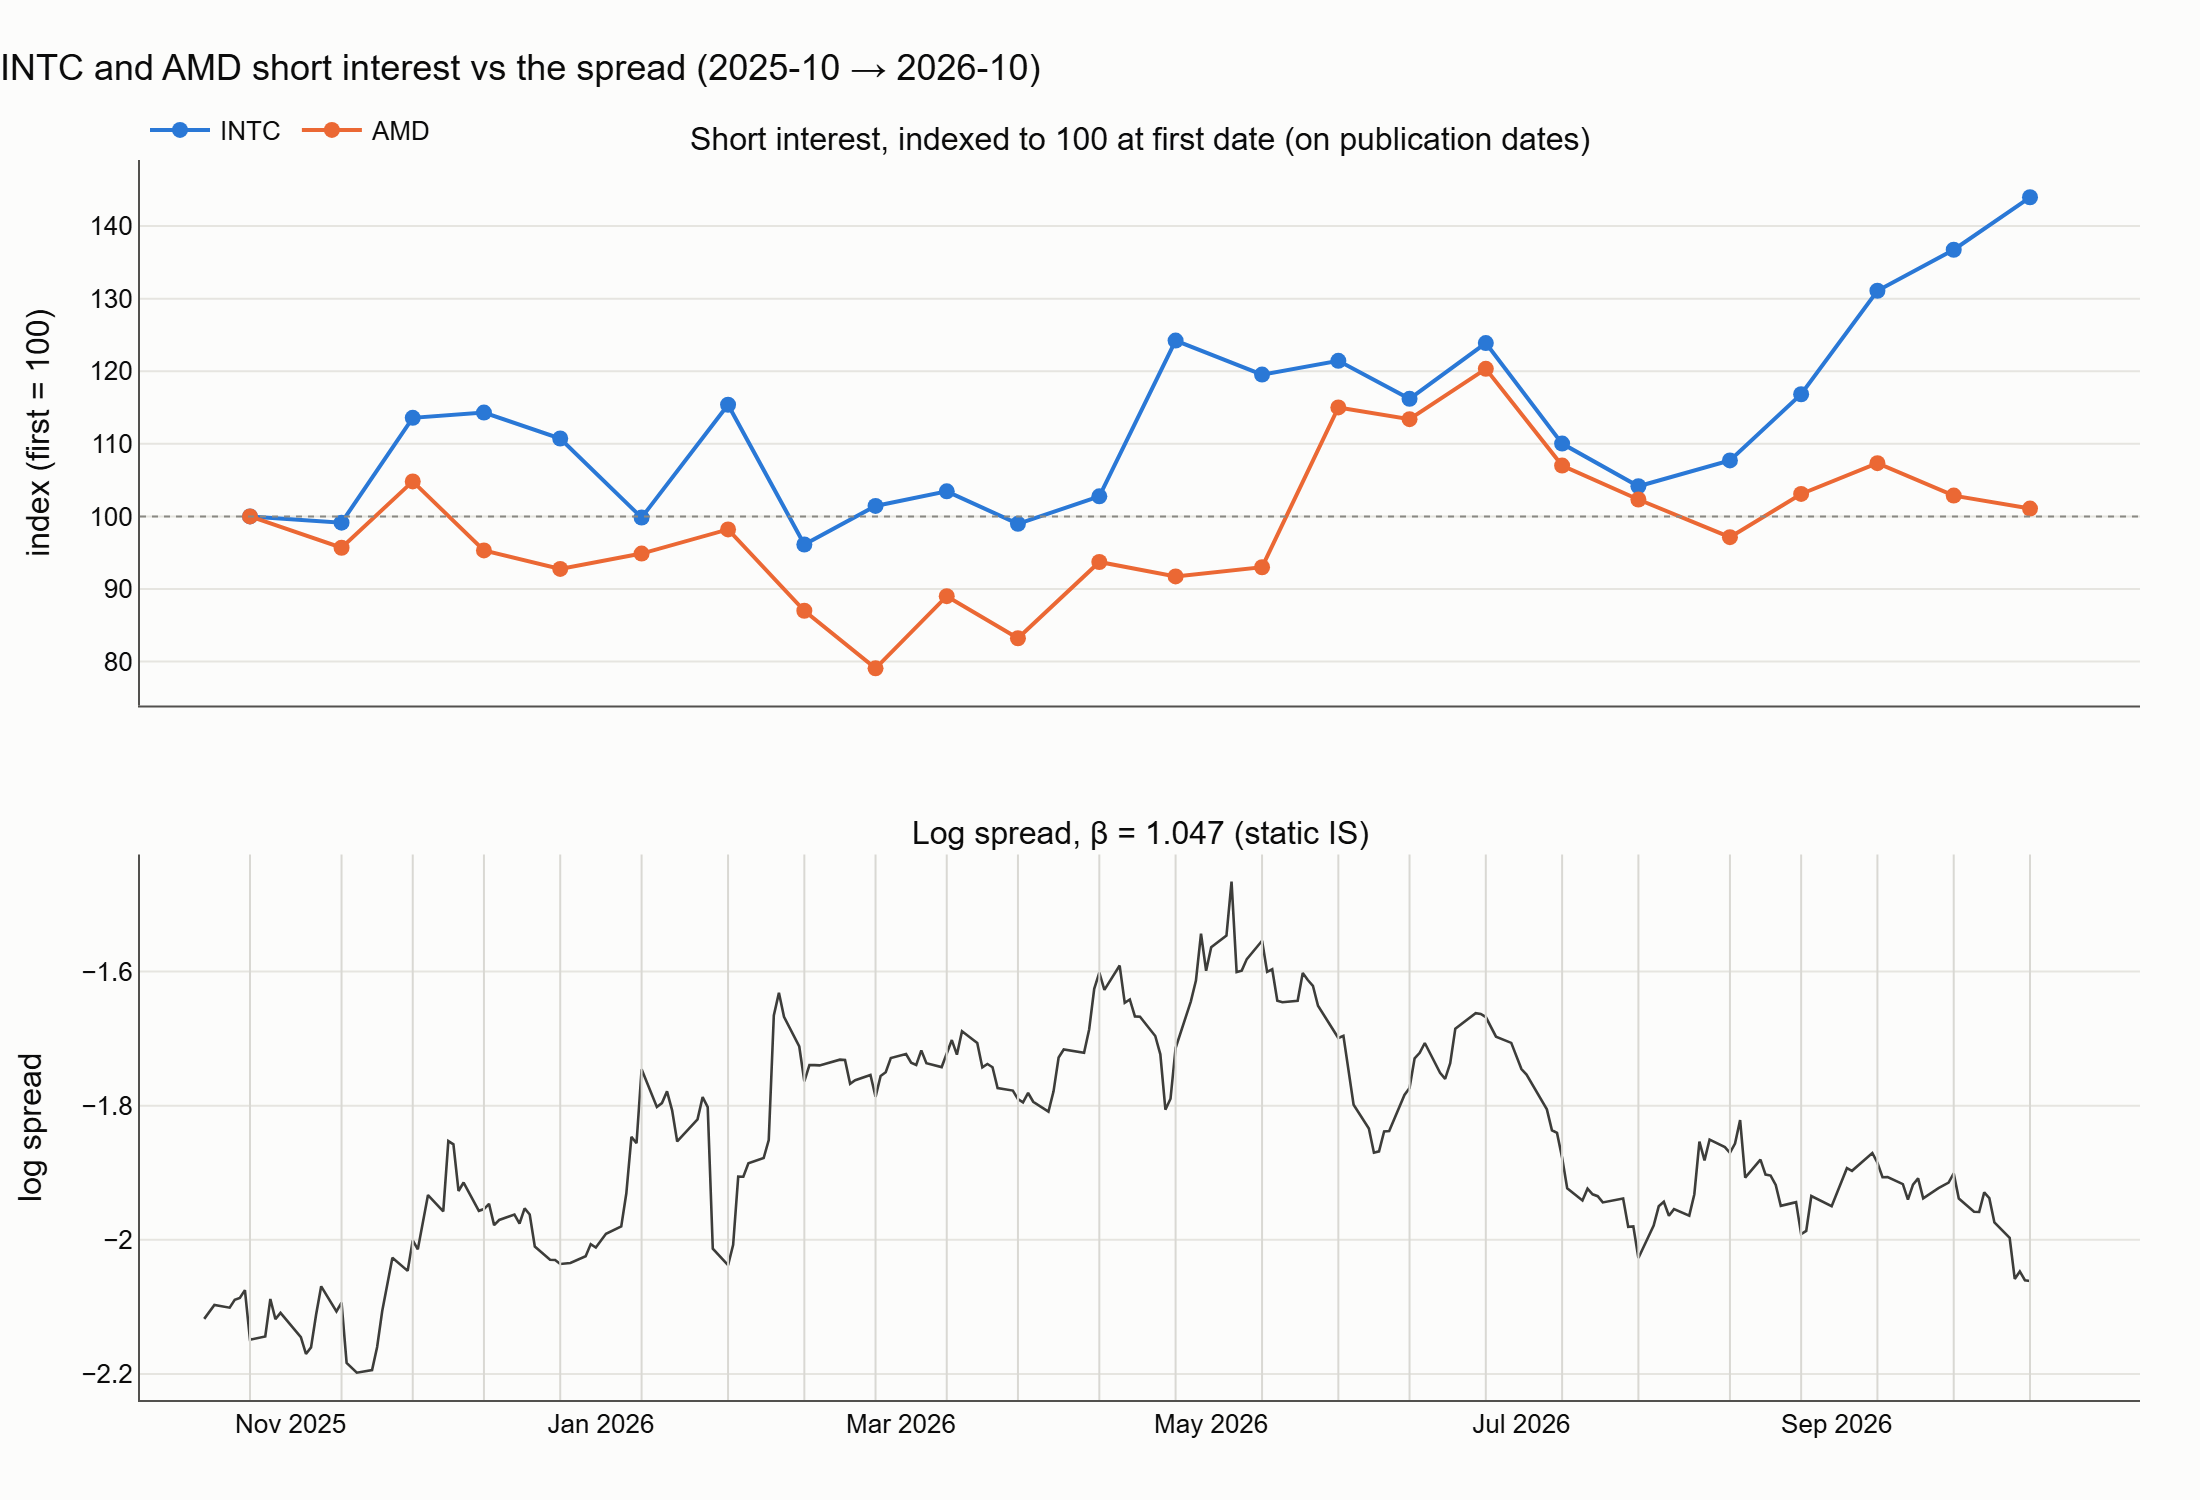

In [4]:
spread = compute_spread(prices, fit.beta)
spread_win = spread[(spread.index >= settle[0]) & (spread.index <= anchors[-1])]

fig = make_subplots(
    rows=2,
    cols=1,
    shared_xaxes=True,
    vertical_spacing=0.12,
    subplot_titles=(
        "Short interest, indexed to 100 at first date (on publication dates)",
        "Log spread, β = 1.047 (static IS)",
    ),
)
for t in (TICKER_A, TICKER_B):
    idx100 = 100 * si[t]["short_interest"] / si[t]["short_interest"].iloc[0]
    fig.add_trace(
        go.Scatter(
            x=anchors,
            y=idx100.to_numpy(),
            name=t,
            mode="lines+markers",
            line={"color": SERIES_COLORS[t], "width": 2},
            marker={"size": 8},
        ),
        row=1,
        col=1,
    )
fig.add_hline(y=100, line={"color": "#8a8984", "width": 1, "dash": "dot"}, row=1, col=1)
fig.add_trace(
    go.Scatter(
        x=spread_win.index,
        y=spread_win,
        name="log spread",
        line={"color": DERIVED_COLOR, "width": 1.3},
        showlegend=False,
    ),
    row=2,
    col=1,
)
for x in anchors:
    fig.add_vline(x=x, line={"color": "#d9d8d3", "width": 1}, row=2, col=1)
apply_style(fig, "INTC and AMD short interest vs the spread (2025-10 → 2026-10)")
fig.update_yaxes(title_text="index (first = 100)", row=1, col=1)
fig.update_yaxes(title_text="log spread", row=2, col=1)
_, png = save_figure(fig, "04a_short_interest_spread", height=750)
display(Image(filename=png))

## The three pre-registered questions (publication-date alignment, main analysis)

ρ = Spearman rank correlation; `rho_crit_5pct` = smallest |ρ| that would be significant at 5% with n = 23; Bonferroni threshold for 5 tests: p < 0.01.

In [5]:
periods = build_periods(si[TICKER_A], si[TICKER_B], prices, fit.beta, end=PRICE_END)
assert len(periods) == 23
tests_pub = spearman_tests(periods)
print(f"Critical |rho| at 5%, n = 23: {critical_spearman(23):.3f}")
tests_pub.round(3)

Critical |rho| at 5%, n = 23: 0.413


,question,x,y,rho,p_value,n,rho_crit_5pct,significant_5pct,significant_bonferroni
0,Q1,si_chg_INTC,spread_chg,-0.145,0.508,23,0.413,False,False
1,Q1,si_chg_AMD,spread_chg,0.099,0.654,23,0.413,False,False
2,Q2,si_chg_diff,spread_chg,-0.276,0.203,23,0.413,False,False
3,Q3,si_chg_INTC,max_abs_ret,0.068,0.757,23,0.413,False,False
4,Q3,si_chg_AMD,max_abs_ret,-0.099,0.654,23,0.413,False,False


### Same tests on settlement-date alignment (descriptive only, no inference)

In [6]:
periods_settle = build_periods(
    si[TICKER_A], si[TICKER_B], prices, fit.beta, end=PRICE_END, use_publication=False
)
spearman_tests(periods_settle)[["question", "x", "y", "rho", "p_value"]].round(3)

,question,x,y,rho,p_value
0,Q1,si_chg_INTC,spread_chg,0.386,0.069
1,Q1,si_chg_AMD,spread_chg,-0.184,0.401
2,Q2,si_chg_diff,spread_chg,0.577,0.004
3,Q3,si_chg_INTC,max_abs_ret,0.162,0.460
4,Q3,si_chg_AMD,max_abs_ret,-0.134,0.541


### The 23 periods (publication alignment)

In [7]:
view = periods.copy()
pct = [c for c in view.columns if c != "start"]
view[pct] = 100 * view[pct]
view = view.rename(
    columns={c: f"{c} %" for c in pct if c != "spread_chg"} | {"spread_chg": "spread_chg x100"}
)
view["start"] = view["start"].dt.date
view.index = view.index.date
view.round(2)

,start,si_chg_INTC %,si_chg_AMD %,spread_chg x100,ret_INTC %,ret_AMD %,max_abs_ret %,si_chg_diff %
2025-11-11,2025-10-24,-0.85,-4.31,5.53,-1.04,-6.09,7.27,3.46
2025-11-25,2025-11-11,14.56,9.55,9.28,-5.41,-13.22,9.00,5.00
2025-12-09,2025-11-25,0.64,-9.08,4.66,13.03,7.51,10.19,9.72
2025-12-24,2025-12-09,-3.13,-2.66,-8.18,-10.72,-2.97,6.15,-0.46
2026-01-09,2025-12-24,-9.84,2.28,29.03,25.97,-5.52,10.80,-12.12
2026-01-26,2026-01-09,15.57,3.50,-29.22,-6.72,23.69,17.03,12.07
2026-02-10,2026-01-26,-16.68,-11.41,27.40,10.92,-15.02,17.31,-5.27
2026-02-24,2026-02-10,5.52,-9.12,-2.30,-2.14,0.13,8.77,14.64
2026-03-10,2026-02-24,1.98,12.57,6.75,1.43,-4.96,5.82,-10.59
2026-03-24,2026-03-10,-4.32,-6.51,-7.09,-5.81,1.05,5.69,2.19


## Observations

- **Main analysis (publication dates): nothing.** None of the 5 pre-registered tests comes close to significance: |ρ| ≤ 0.28 against a 5% critical value of 0.413, smallest p = 0.20 (Q2, ρ = −0.28). Q1: INTC ρ = −0.15 (p = 0.51), AMD ρ = 0.10 (p = 0.65). Q3: INTC ρ = 0.07 (p = 0.76), AMD ρ = −0.10 (p = 0.65). With the short interest known only when it is published, its changes do not line up with the spread or with unusually large moves in this one-year window.
- **Settlement-date alignment (revised after review):** the publication-date alignment I pre-registered compares the spread move with positions measured about 7 business days earlier, so it is neither contemporaneous nor usable in real time. For the brief's descriptive question the natural alignment is the settlement date: relative short interest (INTC − AMD) moved with the spread, ρ = 0.58, p = 0.004, still below the Bonferroni threshold over all 10 correlations (0.005). I report it as an association in one year of data (23 points), not a trading signal.
- **Data quality:** days to cover is exactly 1.0 on 6 of 24 INTC dates and 9 of 24 AMD dates — very likely a floor applied by the source, so that field is not usable as reported.
- **Descriptively:** INTC's short interest drifted up over the year (about +44% by the last date) while AMD's ended close to its starting level; the spread rose until May 2026 and then fell back.
- **Limits:** 23 observations give very low power — only correlations above about 0.41 in absolute value could be detected at 5%; one year is not representative; the publication lag is approximate.